# Lecture : Materials Design

## Lab 01 : Flow Matching for Material Generation -- Demo

### Xavier Bresson


In [1]:
# For Google Colaboratory
# Go to Runtime → Change runtime type → Select T4 GPU to accelerate LM embedding computation
import sys, os
if "google.colab" in sys.modules:
    # mount google drive
    from google.colab import drive
    drive.mount('/content/gdrive')
    path_to_file = '/content/gdrive/My Drive/CS5284_2026_codes/10_Materials_Design/'
    print(path_to_file)
    # change current path to the folder containing "path_to_file"
    os.chdir(path_to_file)
    !pwd
    !python -m pip install -q "pymatgen==2025.6.14" && python -m pip install -q --force-reinstall --no-deps "requests==2.32.4" # Install PyMatGen


In [2]:
# Libraries
import sys
import os
import time
import math
import pickle
import zipfile
from urllib.request import urlretrieve
from contextlib import nullcontext
import torch
import torch.nn as nn
print('PyTorch version:', torch.__version__)
import numpy as np

# Visualization
from itertools import product
import matplotlib.pyplot as plt
from IPython.display import display
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from plotly.colors import qualitative


PyTorch version: 2.14.1


## Load MP20 dataset

In [3]:
# Class of atom dictionary
class Dictionary:
    def __init__(self):
        self.type2idx = {}
        self.idx2type = []
        self.type2num_occurence = {}
        self.idx2num_occurence = []
    def show(self):
        for idx, atom_type in enumerate(self.idx2type):
            print(idx, '\t', atom_type, '\t number of occurrences = {}'.format(self.idx2num_occurence[idx]))
    def __len__(self):
        return len(self.idx2type)

# Class of material
class Material:
    def __init__(self, lattice_matrix, atomic_numbers, frac_coords, num_atoms, atoms_type=None):
        self.lattice_matrix = lattice_matrix
        self.atomic_numbers = atomic_numbers
        self.frac_coords = frac_coords
        self.num_atoms = num_atoms
        self.atoms_type = atoms_type

# Load datasets
print('Loading datasets..')
data_folder_pytorch = 'datasets/'

start = time.time()

# Download and extract datasets if missing
train_file = os.path.join(data_folder_pytorch, 'train_dataset_pytorch.pkl')
atom_file = os.path.join(data_folder_pytorch, 'atom_dict.pkl')

if not os.path.isfile(train_file) or not os.path.isfile(atom_file):
    print('Downloading datasets..')
    os.makedirs(data_folder_pytorch, exist_ok=True)
    url = 'https://www.dropbox.com/scl/fi/8fayswed7az2umjqn2xlq/datasets.zip?rlkey=8toa4qor2ay3bo9oxtraicgv8&dl=1'
    zip_file = os.path.join(data_folder_pytorch, 'datasets.zip')
    def progress(count, size, total):
        if total > 0:
            percent = min(100, int(100 * count * size / total))
            if percent // 10 > progress.last:
                progress.last = percent // 10
                print(f'{progress.last * 10}%', end=' ', flush=True)
    progress.last = -1
    urlretrieve(url, zip_file, reporthook=progress)
    print('\nExtracting datasets..')
    with zipfile.ZipFile(zip_file, 'r') as f:
        f.extractall(data_folder_pytorch)
    os.remove(zip_file)
    if not os.path.isfile(train_file) or not os.path.isfile(atom_file):
        raise FileNotFoundError('Dataset files not found after extraction')
    print('Extraction completed')

# Load atom dictionary and training dataset
with open(atom_file, 'rb') as f:
    atom_dict = pickle.load(f)
with open(train_file, 'rb') as f:
    dataset = pickle.load(f)

print('Time(sec):', time.time() - start)

# Maximum atomic number for normalization
max_atomic_value = max(atom_dict.type2atoNum.values())

# Dataset information
print('Number of training materials:', len(dataset))
print('Number of atom types:', len(atom_dict.idx2type))
print('Maximum atomic value:', max_atomic_value)
print('atom_dict.type2atoNum :',atom_dict.type2atoNum)
print('atom_dict.type2idx :',atom_dict.type2idx)

# One sample
idx = 45
print('dataset[idx].frac_coords ', dataset[idx].frac_coords)
print('dataset[idx].atoms_type ', dataset[idx].atoms_type)
print('dataset[idx].lattice_matrix ', dataset[idx].lattice_matrix)


Loading datasets..
Time(sec): 10.53100299835205
Number of training materials: 27136
Number of atom types: 89
Maximum atomic value: 118
atom_dict.type2atoNum : {'H': 1, 'He': 2, 'Li': 3, 'Be': 4, 'B': 5, 'C': 6, 'N': 7, 'O': 8, 'F': 9, 'Ne': 10, 'Na': 11, 'Mg': 12, 'Al': 13, 'Si': 14, 'P': 15, 'S': 16, 'Cl': 17, 'Ar': 18, 'K': 19, 'Ca': 20, 'Sc': 21, 'Ti': 22, 'V': 23, 'Cr': 24, 'Mn': 25, 'Fe': 26, 'Co': 27, 'Ni': 28, 'Cu': 29, 'Zn': 30, 'Ga': 31, 'Ge': 32, 'As': 33, 'Se': 34, 'Br': 35, 'Kr': 36, 'Rb': 37, 'Sr': 38, 'Y': 39, 'Zr': 40, 'Nb': 41, 'Mo': 42, 'Tc': 43, 'Ru': 44, 'Rh': 45, 'Pd': 46, 'Ag': 47, 'Cd': 48, 'In': 49, 'Sn': 50, 'Sb': 51, 'Te': 52, 'I': 53, 'Xe': 54, 'Cs': 55, 'Ba': 56, 'La': 57, 'Ce': 58, 'Pr': 59, 'Nd': 60, 'Pm': 61, 'Sm': 62, 'Eu': 63, 'Gd': 64, 'Tb': 65, 'Dy': 66, 'Ho': 67, 'Er': 68, 'Tm': 69, 'Yb': 70, 'Lu': 71, 'Hf': 72, 'Ta': 73, 'W': 74, 'Re': 75, 'Os': 76, 'Ir': 77, 'Pt': 78, 'Au': 79, 'Hg': 80, 'Tl': 81, 'Pb': 82, 'Bi': 83, 'Po': 84, 'At': 85, 'Rn': 86, 'F

## Print MP20 dataset statistics

Training material distribution:
Size 1: 59 materials
Size 2: 572 materials
Size 3: 538 materials
Size 4: 4144 materials
Size 5: 1279 materials
Size 6: 2297 materials
Size 7: 572 materials
Size 8: 2119 materials
Size 9: 932 materials
Size 10: 2640 materials
Size 11: 361 materials
Size 12: 2624 materials
Size 13: 585 materials
Size 14: 1770 materials
Size 15: 390 materials
Size 16: 1819 materials
Size 17: 264 materials
Size 18: 1443 materials
Size 19: 287 materials
Size 20: 2441 materials


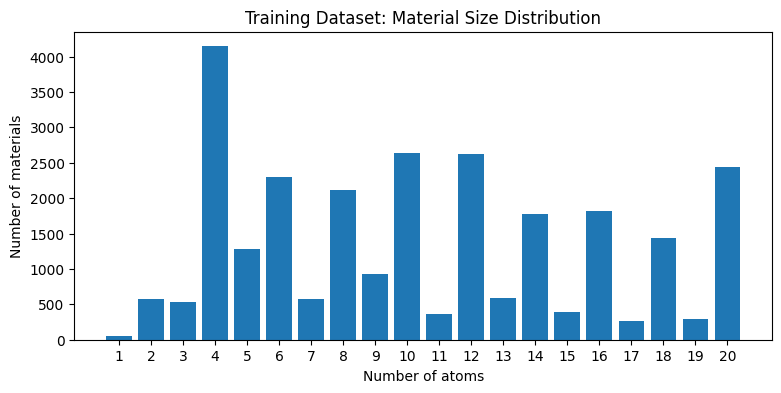

Selected material size: 3
Number of selected materials: 538


In [4]:
# Group training materials by number of atoms
def group_molecules_per_size(dataset):
    mydict = {}
    for mat in dataset:
        num_atoms = mat.num_atoms.item()
        if num_atoms not in mydict:
            mydict[num_atoms] = []
        mydict[num_atoms].append(mat)
    return mydict

# Group all training materials
group_dataset = group_molecules_per_size(dataset)

# Show distribution of material sizes
sizes = sorted(group_dataset.keys())
counts = [len(group_dataset[s]) for s in sizes]

print('Training material distribution:')
for s, count in zip(sizes, counts):
    print(f'Size {s}: {count} materials')

# Plot distribution
plt.figure(figsize=(9, 4))
plt.bar(sizes, counts)
plt.xlabel('Number of atoms')
plt.ylabel('Number of materials')
plt.title('Training Dataset: Material Size Distribution')
plt.xticks(sizes)
plt.show()

# Train only on materials with 3 atoms
sz = 3
max_mat_size = sz
print('Selected material size:', sz)
print('Number of selected materials:', len(group_dataset[sz]))


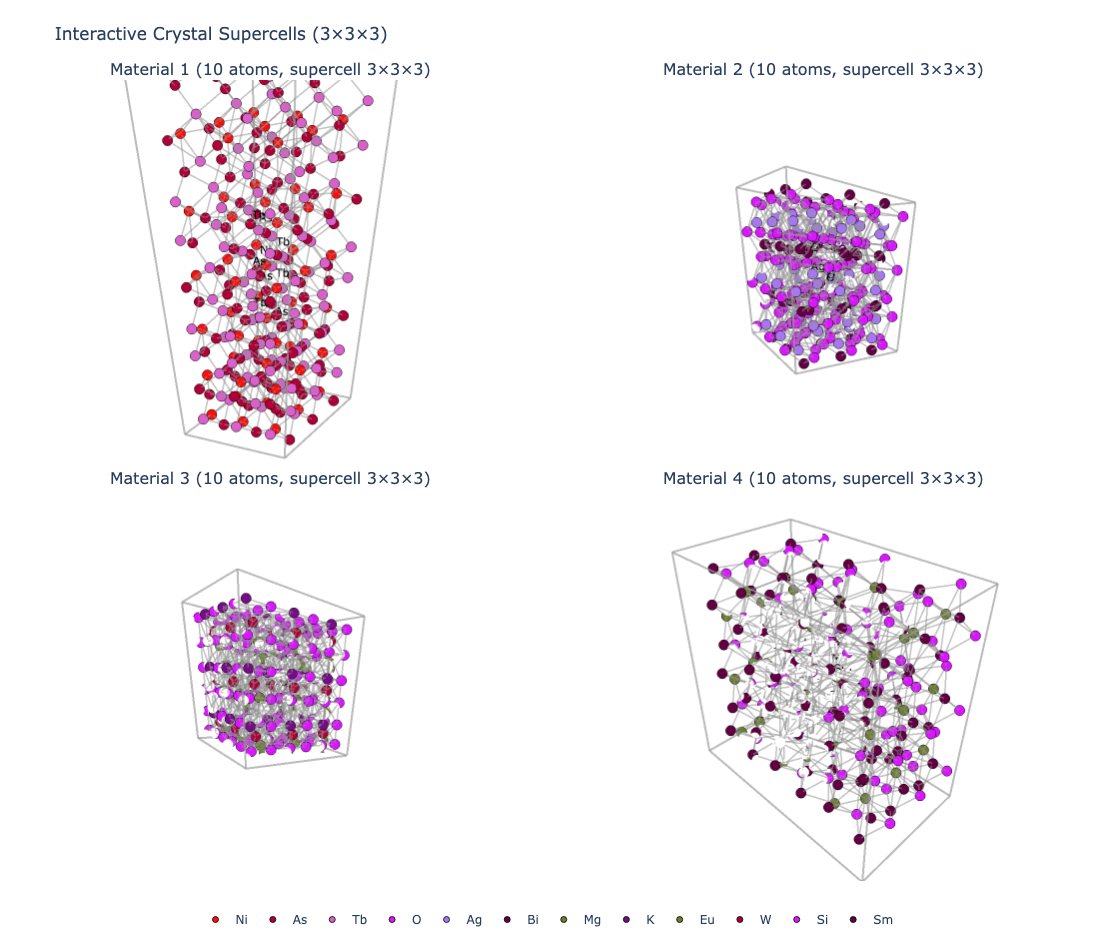

In [5]:
# Interactive 3D visualization of crystal structures as supercells
def plot_material_batch(batch_x1, batch_a1, batch_l1, atom_dict, max_atomic_value, bond_cutoff=3.0, supercell=(3, 3, 3), show_labels=True, label_central_only=True):
    # Convert normalized data to physical coordinates
    x = batch_x1.detach().cpu().numpy()
    a = batch_a1.detach().cpu().numpy() * max_atomic_value
    l = batch_l1.detach().cpu().numpy()
    x = (x * torch.as_tensor(atom_dict.frac_coord_std).cpu().numpy() + torch.as_tensor(atom_dict.frac_coord_mean).cpu().numpy()) % 1.0
    l = l * torch.as_tensor(atom_dict.lattice_std).cpu().numpy() + torch.as_tensor(atom_dict.lattice_mean).cpu().numpy()
    # Convert atomic numbers to chemical elements
    allowed_Z = torch.as_tensor(atom_dict.idx2atoNum_vec).cpu().numpy().astype(int)
    atomic_Z = allowed_Z[np.abs(a[..., None] - allowed_Z).argmin(axis=-1)]
    symbols = {int(z): str(atom_dict.idx2type[k]) for k, z in enumerate(allowed_Z)}
    colors = {int(z): qualitative.Dark24[k % len(qualitative.Dark24)] for k, z in enumerate(allowed_Z)}
    # Create subplot layout
    n = len(x)
    ncols = min(2, n)
    nrows = math.ceil(n / ncols)
    sx, sy, sz = supercell
    titles = [f'Material {i + 1} ({len(x[i])} atoms, supercell {sx}×{sy}×{sz})' for i in range(n)]
    fig = make_subplots(rows=nrows, cols=ncols, specs=[[{'type': 'scene'} for _ in range(ncols)] for _ in range(nrows)], subplot_titles=titles, horizontal_spacing=0.01, vertical_spacing=0.02)
    shown_elements = set()
    center_shift = (sx // 2, sy // 2, sz // 2)
    for i in range(n):
        row = i // ncols + 1
        col = i % ncols + 1
        frac_unit = x[i]
        cell = l[i]
        z_unit = atomic_Z[i]
        # Build supercell
        frac_super_list = []
        z_super_list = []
        label_mask_list = []
        for shift in product(range(sx), range(sy), range(sz)):
            shift_vec = np.array(shift, dtype=float)
            frac_super_list.append(frac_unit + shift_vec)
            z_super_list.append(z_unit)
            if label_central_only:
                label_mask_list.append(np.full(len(frac_unit), shift == center_shift))
            else:
                label_mask_list.append(np.full(len(frac_unit), True))
        frac_super = np.vstack(frac_super_list)
        z_super = np.concatenate(z_super_list)
        label_mask = np.concatenate(label_mask_list)
        xyz = frac_super @ cell
        # Draw supercell edges
        edge_points = []
        super_corners = np.array(list(product([0, sx], [0, sy], [0, sz])), dtype=float)
        for corner in super_corners:
            for axis, scale in enumerate([sx, sy, sz]):
                if corner[axis] == 0:
                    end = corner.copy()
                    end[axis] = scale
                    p0 = corner @ cell
                    p1 = end @ cell
                    edge_points.extend([p0, p1, [np.nan, np.nan, np.nan]])
        edge_points = np.asarray(edge_points)
        fig.add_trace(go.Scatter3d(x=edge_points[:, 0], y=edge_points[:, 1], z=edge_points[:, 2], mode='lines', line=dict(color='rgba(110,110,110,0.7)', width=4), hoverinfo='skip', showlegend=False), row=row, col=col)
        # Draw links between nearby atoms
        bond_points = []
        n_atoms_super = len(xyz)
        for p in range(n_atoms_super):
            for q in range(p + 1, n_atoms_super):
                distance = np.linalg.norm(xyz[q] - xyz[p])
                if 1e-8 < distance <= bond_cutoff:
                    bond_points.extend([xyz[p], xyz[q], [np.nan, np.nan, np.nan]])
        if len(bond_points) > 0:
            bond_points = np.asarray(bond_points)
            fig.add_trace(go.Scatter3d(x=bond_points[:, 0], y=bond_points[:, 1], z=bond_points[:, 2], mode='lines', line=dict(color='rgba(80,80,80,0.55)', width=3), hoverinfo='skip', showlegend=False), row=row, col=col)
        # Draw atoms and labels
        for z in np.unique(z_super):
            z = int(z)
            symbol = symbols.get(z, str(z))
            mask = z_super == z
            positions = xyz[mask]
            if show_labels:
                text_labels = [symbol if flag else '' for flag in label_mask[mask]]
            else:
                text_labels = [''] * len(positions)
            fig.add_trace(go.Scatter3d(x=positions[:, 0], y=positions[:, 1], z=positions[:, 2], mode='markers+text', text=text_labels, textposition='top center', textfont=dict(size=11, color='black'), marker=dict(size=6, color=colors[z], line=dict(color='black', width=0.8)), name=symbol, legendgroup=symbol, showlegend=symbol not in shown_elements, hovertemplate=f'<b>{symbol} (Z={z})</b><br>x=%{{x:.2f}} Å<br>y=%{{y:.2f}} Å<br>z=%{{z:.2f}} Å<extra></extra>'), row=row, col=col)
            shown_elements.add(symbol)
        fig.update_scenes(xaxis=dict(visible=False), yaxis=dict(visible=False), zaxis=dict(visible=False), aspectmode='data', bgcolor='white', row=row, col=col)
    fig.update_layout(title=f'Interactive Crystal Supercells ({sx}×{sy}×{sz})', template='plotly_white', width=1100, height=460 * nrows, margin=dict(l=0, r=0, t=80, b=40), legend=dict(orientation='h', y=-0.03, x=0.5, xanchor='center'))
    fig.show()


# Select 4 training materials with 10 atoms
sz = 10
num_samples = 4
indices = np.random.choice(len(group_dataset[sz]), num_samples, replace=False)
materials = [group_dataset[sz][i] for i in indices]

# Prepare normalized training materials
batch_x_train = torch.stack([m.frac_coords for m in materials]).float()
batch_a_train = torch.stack([m.atomic_numbers for m in materials]).float()
batch_l_train = torch.stack([m.lattice_matrix for m in materials]).float()
batch_x_train = (batch_x_train - atom_dict.frac_coord_mean) / atom_dict.frac_coord_std
batch_a_train = batch_a_train / max_atomic_value
batch_l_train = (batch_l_train - atom_dict.lattice_mean) / atom_dict.lattice_std

# Plot training materials
plot_material_batch(batch_x_train, batch_a_train, batch_l_train, atom_dict, max_atomic_value, bond_cutoff=3.5, supercell=(3, 3, 3))


## Generate a batch of pytorch materials of same size

In [6]:
# Generate batches of materials with a fixed number of atoms
class MaterialSampler:
    def __init__(self, organized_dataset, bs, shuffle=True, sz=3):
        self.bs = bs
        self.sz = sz
        self.counter = 0
        num_mat = len(organized_dataset[sz])
        self.order = np.random.permutation(num_mat) if shuffle else np.arange(num_mat)

    def choose_material_size(self):
        return self.sz

    def is_empty(self):
        return self.counter >= len(self.order)

    def draw_batch_of_materials(self, sz):
        indices = self.order[self.counter:self.counter + self.bs]
        self.counter += len(indices)
        return indices

# Test the sampler
bs = 50
sz = 3
sampler = MaterialSampler(group_dataset, bs, sz=sz)

indices = sampler.draw_batch_of_materials(sz)
minibatch_node = torch.stack([group_dataset[sz][i].atomic_numbers for i in indices])

print('Material size:', sz)
print('batch of indices:', minibatch_node.size())


Material size: 3
batch of indices: torch.Size([50, 3])


## Flow Matching model

In [7]:
# Transformer configuration
d_head = 30
num_heads = 24
d = d_head * num_heads
num_layers = 12

# Dropout configuration
drop_att = 0.125
drop_mha = 0.10
drop_mlp = 0.10

# Fixed material size
sz_fixed = 3
sz_fixed = 7
num_mat = len(group_dataset[sz_fixed])

# EMA
mu_ema = 0.999

print('d:', d)
print('num_layers:', num_layers)
print('num_heads:', num_heads)
print('Number of training materials:', num_mat)


d: 720
num_layers: 12
num_heads: 24
Number of training materials: 572


In [8]:
# Time sampling
def skewed_timestep_sample(num_samples):
    P_mean = -1.2
    P_std = 1.2
    rnd_normal = torch.randn(num_samples)
    sigma = (rnd_normal * P_std + P_mean).exp()
    time = 1 / (1 + sigma)
    return torch.clip(time, min=0.0001, max=1.0)

# Sinusoidal scalar embeddings
def scalar_embedding(scalars, dim, scalar_weight):
    """
    INPUT t: Float tensor of shape (B,)
          dim: dimension for the embeddings
    OUTPUT embedings: Float Tensor of shape (B,dim)
    Remark: the timesteps t in [0,1] are assumed to be in the range [0,1000]
    Each scalar t receive the embedding
    [ cos(omega_0 t) , ...., cos(omega_K t) , sin(omega_0 t), ... , sin(omega_K t) ]
    where K = dim//2
    and the freq omega_0 to omega_K range from omega_0 = 1 to omega_K = 1/10,000.
    """
    scalars = scalar_weight * scalars
    assert dim % 2 == 0
    K = dim // 2
    k_range = torch.arange(K, dtype=torch.float32)
    log_omega = -torch.log(torch.tensor(10000.0)) * k_range / K
    omega = torch.exp(log_omega).to(device=scalars.device)
    exponents = scalars.unsqueeze(-1) * omega
    cosine = torch.cos(exponents)
    sine = torch.sin(exponents)
    embeddings = torch.cat([cosine, sine], dim=-1)
    return embeddings

# Time discretization for ODE generation
def get_time_discretization(nfes, rho=7):
    """
    Construct a nonuniform time grid for flow-matching ODE generation.
    Use a power-law schedule of noise scales from sigma_max=80 to sigma_min=0.002.
    Append sigma=0 so that the final integration time is exactly t=1.
    Convert each noise scale to flow time using t = 1 - sigma / (1 + sigma).
    Args:
        nfes: Number of nonzero noise-scale levels; must be at least 2.
        rho: Controls the spacing between noise-scale levels (default: 7).
    Returns:
        Float64 tensor of shape (nfes + 1,) with increasing times ending at 1.
        The initial time is approximately 1/81, not exactly 0.
    """
    step_indices = torch.arange(nfes, dtype=torch.float64)
    sigma_min = 0.002
    sigma_max = 80.0
    sigma_vec = (sigma_max ** (1 / rho) + step_indices / (nfes - 1) * (sigma_min ** (1 / rho) - sigma_max ** (1 / rho))) ** rho
    sigma_vec = torch.cat([sigma_vec, torch.zeros_like(sigma_vec[:1])])
    time_vec = (sigma_vec / (1 + sigma_vec)).squeeze()
    t_samples = 1.0 - torch.clip(time_vec, min=0.0, max=1.0)
    return t_samples

# RMS normalization
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(d))

    def forward(self, x):
        x_float = x.float()
        norm_x_float = x_float * torch.rsqrt(x_float.pow(2).mean(-1, keepdim=True) + self.eps)
        output = self.weight * norm_x_float.type_as(x)
        return output

# Periodic rotary embeddings for fractional coordinates
def precompute_periodic_3d_rope_harmonics(d_head):
    """
    Periodic 3D RoPE for fractional coordinates on the unit 3-torus T^3.
    Fractional coordinates satisfy u == u + n for every integer vector n. To
    respect this exactly, rotary frequencies must be INTEGER harmonics of 2*pi:
        theta_{axis,m}(u) = 2*pi*m*u_axis,       m = 1, 2, ...
    Hence R(u + 1) = R(u), and for atom-atom attention
        <R(u_i) q_i, R(u_j) k_j>
          = <q_i, R(u_j-u_i) k_j>
    depends only on the relative displacement on the torus. Therefore the
    attention is invariant under the global periodic translation
        u_i -> (u_i + c) % 1.
    IMPORTANT: ordinary log-spaced RoPE frequencies (1, 1/10000, ...) are NOT
    periodic on [0,1), because their phases do not change by an integer multiple
    of 2*pi when u -> u+1.
    """
    assert d_head >= 2
    n_pairs = d_head // 2
    pair_index = torch.arange(n_pairs, dtype=torch.long)
    pair_axis = pair_index % 3
    harmonic = (pair_index // 3 + 1).float()
    return pair_axis, harmonic

def apply_periodic_3d_rotary_emb(x, frac_coords, pair_axis, harmonic):
    """
    Periodic 3D rotary embedding for fractional coordinates.
    Args:
        x:           [B, H, T, d_head]
        frac_coords: [B, T, 3], fractional coordinates; values outside [0,1)
                     are allowed and are wrapped internally with remainder(1).
        pair_axis:   [floor(d_head/2)], x/y/z assignment for each rotary pair.
        harmonic:    [floor(d_head/2)], positive INTEGER Fourier harmonics.
    Returns:
        Tensor with the same shape/dtype as x.
    """
    B, H, T, d_head = x.shape
    n_pairs = d_head // 2
    rotary_dim = 2 * n_pairs
    pair_axis = pair_axis.to(device=frac_coords.device)
    harmonic = harmonic.to(device=frac_coords.device, dtype=torch.float32)
    u = torch.remainder(frac_coords.float(), 1.0)
    angles = 2.0 * math.pi * u[..., pair_axis] * harmonic.view(1, 1, n_pairs)
    cos = angles.cos().unsqueeze(1)
    sin = angles.sin().unsqueeze(1)
    x_rot = x[..., :rotary_dim].float()
    x_even = x_rot[..., 0::2]
    x_odd = x_rot[..., 1::2]
    y_even = x_even * cos - x_odd * sin
    y_odd = x_even * sin + x_odd * cos
    y_rot = torch.stack((y_even, y_odd), dim=-1).flatten(-2)
    if rotary_dim < d_head:
        y = torch.cat((y_rot, x[..., rotary_dim:].float()), dim=-1)
    else:
        y = y_rot
    return y.to(dtype=x.dtype)

# Translation-invariant torus coordinate encoder
class TorusRelativeCoordEncoder(nn.Module):
    """
    PET-inspired translation- and periodic-invariant coordinate encoder on T^3.
    For each central atom i:
        1. Construct an explicit learned self token
            e_i^self = SelfMLP(h_i^a)
        2. For each genuine neighbor j != i, construct a directed edge token
            delta_ij = u_i - u_j
            phi_ij = phi(delta_ij)
            e_ij = EdgeMLP([h_j^a, phi_ij])
        3. The central atom embedding provides the attention query
            q_i = W_Q h_i^a
        4. Atom i attends jointly over
            {e_i^self} U {e_ij : j != i}
        Thus the model can learn how much attention to place on the atom
        itself versus its geometric environment.
    The geometric self-edge e_ii is NOT used. Instead, self-information is
    represented by the separate learned token e_i^self.
    Translation invariance on the unit 3-torus is preserved because all
    coordinate dependence enters only through integer-harmonic Fourier
    features of relative fractional displacements.
    Inputs:
        frac_coords:   [B, N, 3]
        atom_features: [B, N, d]
    Output:
        h_coord:       [B, N, d]
    """
    def __init__(self, d, hidden_d, num_heads):
        super().__init__()
        if d % num_heads != 0:
            raise ValueError(f'd must be divisible by num_heads, got d={d}, num_heads={num_heads}')
        self.d = d
        self.num_heads = num_heads
        self.d_head = d // num_heads
        self.attn_scale = self.d_head ** -0.5
        self.num_harmonics = d // 6
        if self.num_harmonics < 1:
            raise ValueError(f'd must be at least 6 for periodic Fourier features, got d={d}')
        periodic_feature_dim = 6 * self.num_harmonics
        edge_input_dim = d + periodic_feature_dim
        self.edge_mlp = nn.Sequential(nn.Linear(edge_input_dim, hidden_d), nn.SiLU(), nn.Linear(hidden_d, d))
        self.self_mlp = nn.Sequential(nn.Linear(d, hidden_d), nn.SiLU(), nn.Linear(hidden_d, d))
        self.center_norm = RMSNorm(d)
        self.edge_norm = RMSNorm(d)
        self.self_norm = RMSNorm(d)
        self.q_proj = nn.Linear(d, d, bias=False)
        self.k_proj = nn.Linear(d, d, bias=False)
        self.v_proj = nn.Linear(d, d, bias=False)
        self.out_proj = nn.Linear(d, d, bias=False)
        self.ffn_norm = RMSNorm(d)
        self.ffn = nn.Sequential(nn.Linear(d, hidden_d, bias=False), nn.SiLU(), nn.Linear(hidden_d, d, bias=False))

    def forward(self, frac_coords, atom_features):
        if frac_coords.ndim != 3 or frac_coords.shape[-1] != 3:
            raise ValueError(f'frac_coords must have shape [B,N,3], got {tuple(frac_coords.shape)}')
        if atom_features.ndim != 3:
            raise ValueError(f'atom_features must have shape [B,N,d], got {tuple(atom_features.shape)}')
        if atom_features.shape[:2] != frac_coords.shape[:2]:
            raise ValueError('atom_features and frac_coords must have the same [B,N] dimensions')
        if atom_features.shape[-1] != self.d:
            raise ValueError(f'atom_features last dimension must be {self.d}, got {atom_features.shape[-1]}')
        out_dtype = atom_features.dtype
        u = torch.remainder(frac_coords.float(), 1.0)
        B, N, _ = u.shape
        atom_features_float = atom_features.to(device=u.device, dtype=u.dtype)
        self_tokens = self.self_mlp(atom_features_float)
        delta = u.unsqueeze(2) - u.unsqueeze(1)
        harmonics = torch.arange(1, self.num_harmonics + 1, device=u.device, dtype=u.dtype)
        angles = 2.0 * math.pi * delta.unsqueeze(-1) * harmonics.view(1, 1, 1, 1, -1)
        pair_features = torch.cat((angles.cos(), angles.sin()), dim=-1)
        pair_features = pair_features.flatten(start_dim=-2)
        neighbor_features = atom_features_float.unsqueeze(1).expand(-1, N, -1, -1)
        edge_input = torch.cat((neighbor_features, pair_features), dim=-1)
        edge_input_2d = edge_input.reshape(B * N * N, edge_input.shape[-1])
        edge_tokens_2d = self.edge_mlp(edge_input_2d)
        edge_tokens = edge_tokens_2d.reshape(B, N, N, self.d)
        q = self.q_proj(self.center_norm(atom_features_float))
        q = q.view(B, N, self.num_heads, self.d_head)
        self_tokens_norm = self.self_norm(self_tokens)
        self_k = self.k_proj(self_tokens_norm)
        self_v = self.v_proj(self_tokens_norm)
        self_k = self_k.view(B, N, 1, self.num_heads, self.d_head)
        self_v = self_v.view(B, N, 1, self.num_heads, self.d_head)
        edge_tokens_norm = self.edge_norm(edge_tokens)
        edge_k = self.k_proj(edge_tokens_norm)
        edge_v = self.v_proj(edge_tokens_norm)
        edge_k = edge_k.view(B, N, N, self.num_heads, self.d_head)
        edge_v = edge_v.view(B, N, N, self.num_heads, self.d_head)
        all_k = torch.cat((self_k, edge_k), dim=2)
        all_v = torch.cat((self_v, edge_v), dim=2)
        att_logits = (q.unsqueeze(2) * all_k).sum(dim=-1) * self.attn_scale
        edge_self_mask = torch.eye(N, device=u.device, dtype=torch.bool)
        attention_mask = torch.zeros(N, N + 1, device=u.device, dtype=torch.bool)
        attention_mask[:, 1:] = edge_self_mask
        att_logits = att_logits.masked_fill(attention_mask.view(1, N, N + 1, 1), float('-inf'))
        att_weights = torch.softmax(att_logits.float(), dim=2).to(dtype=all_v.dtype)
        context = (att_weights.unsqueeze(-1) * all_v).sum(dim=2)
        context = context.reshape(B, N, self.d)
        attn_update = self.out_proj(context)
        ffn_update = self.ffn(self.ffn_norm(attn_update))
        h_coord = attn_update + ffn_update
        return h_coord.to(dtype=out_dtype)

# Multi-head attention with periodic 3D RoPE
class MHA(nn.Module):
    def __init__(self, d, n_heads):
        super().__init__()
        assert d % n_heads == 0
        d_head = d // n_heads
        self.d_head = d_head
        self.n_heads = n_heads
        self.Q = nn.Linear(d, d, bias=False)
        self.K = nn.Linear(d, d, bias=False)
        self.V = nn.Linear(d, d, bias=False)
        self.WO = nn.Linear(d, d, bias=False)
        self.drop_att = nn.Dropout(drop_att)
        pair_axis, harmonic = precompute_periodic_3d_rope_harmonics(d_head)
        self.register_buffer('rope_pair_axis', pair_axis, persistent=False)
        self.register_buffer('rope_harmonic', harmonic, persistent=False)

    def forward(self, x, atom_frac_coords):
        q, k, v = self.Q(x), self.K(x), self.V(x)
        bsz, setsize, _ = x.shape
        n_atoms = setsize - 1
        assert atom_frac_coords.shape[:2] == (bsz, n_atoms)
        q = q.view(bsz, setsize, self.n_heads, self.d_head).transpose(1, 2).contiguous()
        k = k.view(bsz, setsize, self.n_heads, self.d_head).transpose(1, 2).contiguous()
        v = v.view(bsz, setsize, self.n_heads, self.d_head).transpose(1, 2).contiguous()
        q_rot = q.clone()
        k_rot = k.clone()
        q_rot[:, :, 1:, :] = apply_periodic_3d_rotary_emb(q[:, :, 1:, :], atom_frac_coords, self.rope_pair_axis, self.rope_harmonic)
        k_rot[:, :, 1:, :] = apply_periodic_3d_rotary_emb(k[:, :, 1:, :], atom_frac_coords, self.rope_pair_axis, self.rope_harmonic)
        att_scores = q_rot @ k_rot.transpose(2, 3).contiguous()
        att_scores[:, :, 0, :] = (q[:, :, 0, :].unsqueeze(2) @ k.transpose(2, 3).contiguous()).squeeze(2)
        att_scores[:, :, :, 0] = (q @ k[:, :, 0, :].unsqueeze(-1)).squeeze(-1)
        att_scores = att_scores / math.sqrt(self.d_head)
        att_scores = torch.softmax(att_scores.float(), dim=3).type_as(x)
        att_scores = self.drop_att(att_scores)
        h = att_scores @ v
        h = h.transpose(1, 2).contiguous().view(bsz, setsize, -1)
        h = self.WO(h)
        return h

# SwiGLU feedforward network
class MLP_SwiGLU(nn.Module):
    def __init__(self, d):
        super().__init__()
        hidden_d = int(2 / 3 * d)
        self.linear1 = nn.Linear(d, hidden_d, bias=False)
        self.linear2 = nn.Linear(hidden_d, d, bias=False)
        self.linear3 = nn.Linear(d, hidden_d, bias=False)

    def forward(self, x):
        h = self.linear2(nn.SiLU()(self.linear1(x)) * self.linear3(x))
        return h

# Transformer block
class BlockGT(nn.Module):
    def __init__(self, d, num_heads):
        super().__init__()
        self.RMSNorm_MHA = RMSNorm(d)
        self.MHA = MHA(d, num_heads)
        self.drop_mha = nn.Dropout(drop_mha)
        self.RMSNorm_MLP = RMSNorm(d)
        self.MLP_SwiGLU = MLP_SwiGLU(d)
        self.drop_mlp = nn.Dropout(drop_mlp)

    def forward(self, x, atom_frac_coords):
        x_norm = self.RMSNorm_MHA(x)
        x = x + self.drop_mha(self.MHA(x_norm, atom_frac_coords))
        x_norm = self.RMSNorm_MLP(x)
        x = x + self.drop_mlp(self.MLP_SwiGLU(x_norm))
        return x

# Transformer model
class Transformer(nn.Module):
    """
    Transformer velocity predictor for crystal flow matching.
    Inputs:
        x_t: [B, N, 3] standardized fractional-coordinate state.
        a_t: [B, N] normalized atomic-number state.
        l_t: [B, 3, 3] standardized lattice-matrix state.
        sample_t: [B] flow-matching times in [0, 1].
    Architecture:
        Embed time and atomic numbers with sinusoidal features and learned MLPs.
        Recover a wrapped fractional-coordinate proxy from x_t only for geometry.
        Encode periodic relative atomic geometry with a learned self token and edges.
        Form one lattice/CLS token and N atom tokens, then apply Transformer blocks.
        Use periodic 3D RoPE for atom-atom attention; leave CLS interactions unrotated.
        Decode separate velocity predictions for coordinates, atoms, and lattice.
    Returns:
        ut_x_pred: [B, N, 3] coordinate velocity in standardized space.
        ut_a_pred: [B, N] atomic-number velocity in normalized space.
        ut_l_pred: [B, 3, 3] lattice velocity in standardized space.
    """
    def __init__(self):
        super().__init__()
        hidden_d = int(3 / 2 * d)
        self.t_enc = nn.Sequential(nn.Linear(d, hidden_d), nn.SiLU(), nn.Linear(hidden_d, d))
        self.x_t_enc = TorusRelativeCoordEncoder(d=d, hidden_d=hidden_d, num_heads=num_heads)
        frac_mean = torch.as_tensor(atom_dict.frac_coord_mean, dtype=torch.float32)
        frac_std = torch.as_tensor(atom_dict.frac_coord_std, dtype=torch.float32)
        if torch.any(frac_std <= 0):
            raise ValueError('atom_dict.frac_coord_std must be strictly positive')
        self.register_buffer('frac_coord_mean', frac_mean.clone(), persistent=True)
        self.register_buffer('frac_coord_std', frac_std.clone(), persistent=True)
        self.a_t_enc = nn.Sequential(nn.Linear(d, hidden_d), nn.SiLU(), nn.Linear(hidden_d, d))
        self.l_t_enc = nn.Sequential(nn.Linear(9, hidden_d), nn.SiLU(), nn.Linear(hidden_d, d))
        self.gt_layers = nn.ModuleList([BlockGT(d, num_heads) for _ in range(num_layers)])
        self.ut_x_dec = nn.Sequential(nn.Linear(d, hidden_d), nn.SiLU(), nn.Linear(hidden_d, 3))
        self.ut_a_dec = nn.Sequential(nn.Linear(d, hidden_d), nn.SiLU(), nn.Linear(hidden_d, 1))
        self.ut_l_dec = nn.Sequential(nn.Linear(d, hidden_d), nn.SiLU(), nn.Linear(hidden_d, 9))

    def forward(self, x_t, a_t, l_t, sample_t):
        p_t = self.t_enc(scalar_embedding(sample_t, d, 1000.0))
        frac_mean = self.frac_coord_mean.to(device=x_t.device, dtype=x_t.dtype)
        frac_std = self.frac_coord_std.to(device=x_t.device, dtype=x_t.dtype)
        x_frac_proxy = x_t * frac_std + frac_mean
        x_frac_geom = torch.remainder(x_frac_proxy, 1.0)
        a_t = scalar_embedding(a_t, d, 1000.0)
        h_a_t = self.a_t_enc(a_t)
        h_x_t = self.x_t_enc(x_frac_geom, h_a_t)
        h_l_t = self.l_t_enc(l_t.reshape(-1, 9)).unsqueeze(1)
        h_atoms = h_x_t + h_a_t
        h_t = torch.cat([h_l_t, h_atoms], dim=1)
        for gt_layer in self.gt_layers:
            h_t = h_t + p_t.unsqueeze(1)
            h_t = gt_layer(h_t, x_frac_geom)
        h_t_l = h_t[:, 0, :]
        h_t_atoms = h_t[:, 1:, :]
        ut_x_pred = self.ut_x_dec(h_t_atoms)
        ut_a_pred = self.ut_a_dec(h_t_atoms).squeeze()
        ut_l_pred = self.ut_l_dec(h_t_l).reshape(-1, 3, 3)
        return ut_x_pred, ut_a_pred, ut_l_pred

# Flow matching model
class FM(nn.Module):
    """
    Flow-matching model for predicting and integrating crystal-state velocities.
    forward(x_t, a_t, l_t, sample_t) predicts coordinate, atom, and lattice velocities.
    improved_euler(x0, a0, l0, time_grid) integrates the learned ODE using two
    velocity evaluations per time interval (predictor and corrected average).
    generate_process_fm(num_mol, size_mol, num_time_steps=100) samples initial
    Gaussian coordinates/lattices and uniform atomic-number states, then integrates.
    Inputs to generation:
        num_mol: Number of crystal structures to generate.
        size_mol: Number of atoms per generated structure.
        num_time_steps: Number of nonzero noise-scale levels in the ODE time grid.
    Returns from generation:
        X_1: [num_mol, size_mol, 3] standardized coordinate states.
        A_1: [num_mol, size_mol] normalized atomic-number states.
        L_1: [num_mol, 3, 3] standardized lattice states.
    The ODE operates in model space; convert coordinates and lattice back to
    physical units and wrap fractional coordinates only for visualization/export.
    """
    def __init__(self):
        super().__init__()
        self.Transformer = Transformer()

    def forward(self, x_t, a_t, l_t, sample_t):
        u_t_x_pred, u_t_a_pred, u_t_l_pred = self.Transformer(x_t, a_t, l_t, sample_t)
        return u_t_x_pred, u_t_a_pred, u_t_l_pred

    def improved_euler(self, x0, a0, l0, time_grid):
        bs = x0.shape[0]
        x = x0
        a = a0
        l = l0
        for i in range(len(time_grid) - 1):
            t = time_grid[i].item()
            t_prime = time_grid[i + 1].item()
            dt = t_prime - t
            t1 = torch.full(size=(bs,), fill_value=t).to(device)
            with torch.no_grad():
                v1_x, v1_a, v1_l = self.forward(x, a, l, t1)
            x_temp = x + dt * v1_x
            a_temp = a + dt * v1_a
            l_temp = l + dt * v1_l
            t2 = torch.full(size=(bs,), fill_value=t_prime).to(device)
            with torch.no_grad():
                v2_x, v2_a, v2_l = self.forward(x_temp, a_temp, l_temp, t2)
            x = x + dt * (v1_x + v2_x) / 2
            a = a + dt * (v1_a + v2_a) / 2
            l = l + dt * (v1_l + v2_l) / 2
        return x, a, l

    def generate_process_fm(self, num_mol, size_mol, num_time_steps=100):
        time_grid = get_time_discretization(num_time_steps)
        X_0 = torch.randn(size=(num_mol, size_mol, 3), dtype=torch.float32).to(device)
        A_0 = torch.rand(size=(num_mol, size_mol), dtype=torch.float32).to(device)
        L_0 = torch.randn(size=(num_mol, 3, 3), dtype=torch.float32).to(device)
        X_1, A_1, L_1 = self.improved_euler(X_0, A_0, L_0, time_grid)
        return X_1, A_1, L_1

# Parameter counting
def count(modules):
    if isinstance(modules, list):
        return sum(sum(p.numel() for p in m.parameters() if p.requires_grad) for m in modules) / 1e6
    return sum(p.numel() for p in modules.parameters() if p.requires_grad) / 1e6

# Canonical fractional coordinates
def canonical_frac_coords(frac_coords, eps=1e-6):
    frac_coords = frac_coords % 1.0
    frac_coords = torch.where((frac_coords < eps) | (frac_coords > 1.0 - eps), torch.zeros_like(frac_coords), frac_coords)
    return frac_coords

# Initialize model and EMA model
device = 'cpu'
net = FM().to(device)
print('num_param (million):', count(net))
print('Block Time:', count([net.Transformer.t_enc]))
print('Block Encoders:', count([net.Transformer.a_t_enc, net.Transformer.l_t_enc]))
print('Block GT Layers:', count([net.Transformer.gt_layers]))
print('Block Decoders:', count([net.Transformer.ut_x_dec, net.Transformer.ut_a_dec, net.Transformer.ut_l_dec]))
ema_net = FM().to(device)
ema_net.load_state_dict(net.state_dict())

# Test one training step
init_lr = 0.001
optimizer = torch.optim.AdamW(net.parameters(), lr=init_lr)
sampler = MaterialSampler(group_dataset, bs, sz=sz_fixed)
sz = sampler.choose_material_size()
indices = sampler.draw_batch_of_materials(sz)
batch_size = len(indices)
batch_sample_t = skewed_timestep_sample(batch_size).to(device)

X1 = torch.stack([group_dataset[sz][i].frac_coords for i in indices]).float().to(device)
X1 = X1 + torch.empty(batch_size, 3).uniform_(0.0, 1.0).unsqueeze(1).to(device)
X1 = X1 - X1.floor()
X1 = canonical_frac_coords(X1).to(device)
X1 = (X1 - atom_dict.frac_coord_mean) / atom_dict.frac_coord_std
X0 = torch.randn_like(X1).to(device)
Xt = (1 - batch_sample_t.view(batch_size, 1, 1)) * X0 + batch_sample_t.view(batch_size, 1, 1) * X1
Ut_X = X1 - X0

A1 = torch.stack([group_dataset[sz][i].atomic_numbers for i in indices]).float().to(device)
A1 = A1 / max_atomic_value
A0 = torch.rand_like(A1)
At = (1 - batch_sample_t.view(batch_size, 1)) * A0 + batch_sample_t.view(batch_size, 1) * A1
Ut_A = A1 - A0

L1 = torch.stack([group_dataset[sz][i].lattice_matrix for i in indices]).float().to(device)
L1 = (L1 - atom_dict.lattice_mean) / atom_dict.lattice_std
L0 = torch.randn_like(L1).to(device)
t_lattice = batch_sample_t.view(batch_size, 1, 1)
Lt = (1.0 - t_lattice) * L0 + t_lattice * L1
Ut_L = L1 - L0

# Forward and backward passes
Ut_X_pred, Ut_A_pred, Ut_L_pred = net(Xt, At, Lt, batch_sample_t)
print('Ut_X_pred:', Ut_X_pred.size())
print('Ut_A_pred:', Ut_A_pred.size())
print('Ut_L_pred:', Ut_L_pred.size())
weight_X = 1.0 / 3.0
weight_A = 1.0 / 3.0
weight_L = 1.0 / 3.0
mse_loss = nn.MSELoss()
loss_FM = weight_X * mse_loss(Ut_X_pred, Ut_X) + weight_A * mse_loss(Ut_A_pred, Ut_A) + weight_L * mse_loss(Ut_L_pred, Ut_L)
batch_weight = batch_size / bs
loss = batch_weight * loss_FM
optimizer.zero_grad()
loss.backward()
torch.nn.utils.clip_grad_norm_(net.parameters(), 0.25)
optimizer.step()

# Generate 4 materials
with torch.no_grad():
    batch_x1, batch_a1, batch_l1 = net.generate_process_fm(4, sz_fixed, 100)
    print('batch_x1', batch_x1.size())
    print('batch_a1', batch_a1.size())
    print('batch_l1', batch_l1.size())


num_param (million): 51.118573
Block Time: 1.557
Block Encoders: 2.34612
Block GT Layers: 37.34208
Block Decoders: 2.350093
Ut_X_pred: torch.Size([50, 7, 3])
Ut_A_pred: torch.Size([50, 7])
Ut_L_pred: torch.Size([50, 3, 3])
batch_x1 torch.Size([4, 7, 3])
batch_a1 torch.Size([4, 7])
batch_l1 torch.Size([4, 3, 3])


## Training

Device: cuda:0 | bfloat16 autocast: True
GPU: Tesla T4
Training materials: 572 | Steps per epoch: 18
Epoch 1/100 | loss=1.490450 | lr=0.0003000 | elapsed=0.04 min
Epoch 5/100 | loss=0.965035 | lr=0.0002984 | elapsed=0.21 min


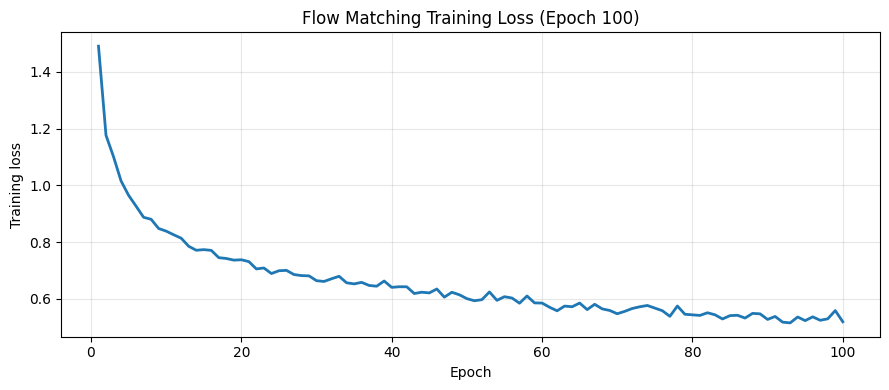

Epoch 10/100 | loss=0.838664 | lr=0.0002931 | elapsed=0.43 min
Epoch 15/100 | loss=0.773398 | lr=0.0002843 | elapsed=0.65 min
Epoch 20/100 | loss=0.737753 | lr=0.0002722 | elapsed=0.85 min
Epoch 25/100 | loss=0.699046 | lr=0.0002571 | elapsed=1.06 min
Epoch 30/100 | loss=0.663974 | lr=0.0002393 | elapsed=1.27 min
Epoch 35/100 | loss=0.652727 | lr=0.0002194 | elapsed=1.48 min
Epoch 40/100 | loss=0.640529 | lr=0.0001977 | elapsed=1.69 min
Epoch 45/100 | loss=0.620934 | lr=0.0001749 | elapsed=1.90 min
Epoch 50/100 | loss=0.600691 | lr=0.0001514 | elapsed=2.11 min
Epoch 55/100 | loss=0.607605 | lr=0.0001280 | elapsed=2.32 min
Epoch 60/100 | loss=0.585132 | lr=0.0001050 | elapsed=2.53 min
Epoch 65/100 | loss=0.585235 | lr=0.0000833 | elapsed=2.74 min
Epoch 70/100 | loss=0.547485 | lr=0.0000632 | elapsed=2.96 min
Epoch 75/100 | loss=0.567442 | lr=0.0000452 | elapsed=3.17 min
Epoch 80/100 | loss=0.543646 | lr=0.0000299 | elapsed=3.37 min
Epoch 85/100 | loss=0.540911 | lr=0.0000175 | elapsed=3

In [11]:
# Training loop: GPU when available, CPU otherwise
from contextlib import nullcontext

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda' and torch.cuda.is_bf16_supported()
print('Device:', device, '| bfloat16 autocast:', use_amp)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

from IPython.display import display
plot_handle = None

# Training configuration
nb_epochs = 1000
nb_epochs = 100
# nb_epochs = 10
bs = 32
max_lr = 3e-4
min_lr = 1e-6
warmup_steps = 5
weight_decay = 0.1
plot_every = 5

# Models and exponential moving average (EMA)
net = FM().to(device)
ema_net = FM().to(device)
ema_net.load_state_dict(net.state_dict())
ema_net.eval()
ema_net.requires_grad_(False)

@torch.no_grad()
def update_ema_net(mu_ema, step):
    decay = min(mu_ema, (1 + step) / (10 + step))
    for ema_param, param in zip(ema_net.parameters(), net.parameters()):
        ema_param.lerp_(param, 1.0 - decay)
    for ema_buffer, buffer in zip(ema_net.buffers(), net.buffers()):
        ema_buffer.copy_(buffer)

# AdamW optimizer
params_decay = [p for p in net.parameters() if p.requires_grad and p.ndim >= 2]
params_no_decay = [p for p in net.parameters() if p.requires_grad and p.ndim < 2]
optimizer = torch.optim.AdamW([{'params': params_decay, 'weight_decay': weight_decay}, {'params': params_no_decay, 'weight_decay': 0.0}], lr=max_lr, betas=(0.9, 0.95), eps=1e-8)
mse_loss = nn.MSELoss()

# Learning rate: warmup followed by cosine decay
num_step_per_epoch = math.ceil(len(group_dataset[sz_fixed]) / bs)
if num_step_per_epoch == 0:
    raise ValueError(f'No training materials with sz_fixed={sz_fixed}')
max_steps = nb_epochs * num_step_per_epoch
warmup_steps = min(warmup_steps, max_steps - 1)

def get_lr(step):
    if step < warmup_steps:
        return max_lr * (step + 1) / warmup_steps
    if step >= max_steps:
        return min_lr
    decay_ratio = (step - warmup_steps) / (max_steps - warmup_steps)
    return min_lr + 0.5 * (1 + math.cos(math.pi * decay_ratio)) * (max_lr - min_lr)

# Normalization statistics
frac_mean = torch.as_tensor(atom_dict.frac_coord_mean, device=device, dtype=torch.float32)
frac_std = torch.as_tensor(atom_dict.frac_coord_std, device=device, dtype=torch.float32)
lattice_mean = torch.as_tensor(atom_dict.lattice_mean, device=device, dtype=torch.float32)
lattice_std = torch.as_tensor(atom_dict.lattice_std, device=device, dtype=torch.float32)

# Training history and loss plots
loss_history = []
total_steps = 0
start = time.time()
print('Training materials:', len(group_dataset[sz_fixed]), '| Steps per epoch:', num_step_per_epoch)

# Training loop
for epoch in range(1, nb_epochs + 1):

    net.train()
    sampler = MaterialSampler(group_dataset, bs, sz=sz_fixed)
    running_loss = 0.0
    num_materials = 0

    while not sampler.is_empty():
        indices = sampler.draw_batch_of_materials(sz_fixed)
        batch_size = len(indices)
        t = skewed_timestep_sample(batch_size).to(device)
        t_x = t.view(batch_size, 1, 1)
        t_a = t.view(batch_size, 1)

        # Fractional coordinates
        X1 = torch.stack([group_dataset[sz_fixed][i].frac_coords for i in indices]).to(device=device, dtype=torch.float32)
        X1 = canonical_frac_coords(X1 + torch.rand(batch_size, 1, 3, device=device))
        X1 = (X1 - frac_mean) / frac_std
        X0 = torch.randn_like(X1)
        Xt = (1 - t_x) * X0 + t_x * X1
        Ut_X = X1 - X0

        # Atomic numbers
        A1 = torch.stack([group_dataset[sz_fixed][i].atomic_numbers for i in indices]).to(device=device, dtype=torch.float32) / max_atomic_value
        A0 = torch.rand_like(A1)
        At = (1 - t_a) * A0 + t_a * A1
        Ut_A = A1 - A0

        # Lattice matrices
        L1 = torch.stack([group_dataset[sz_fixed][i].lattice_matrix for i in indices]).to(device=device, dtype=torch.float32)
        L1 = (L1 - lattice_mean) / lattice_std
        L0 = torch.randn_like(L1)
        Lt = (1 - t_x) * L0 + t_x * L1
        Ut_L = L1 - L0

        # Forward pass and loss
        with (torch.autocast(device_type='cuda', dtype=torch.bfloat16) if use_amp else nullcontext()):
            Ut_X_pred, Ut_A_pred, Ut_L_pred = net(Xt, At, Lt, t)
            loss_FM = (mse_loss(Ut_X_pred, Ut_X) + mse_loss(Ut_A_pred, Ut_A) + mse_loss(Ut_L_pred, Ut_L)) / 3
            loss = (batch_size / bs) * loss_FM

        # Backward pass and optimization
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
        lr = get_lr(total_steps)
        for group in optimizer.param_groups:
            group['lr'] = lr
        optimizer.step()
        update_ema_net(mu_ema, total_steps)
        total_steps += 1
        running_loss += loss_FM.detach().item() * batch_size
        num_materials += batch_size

    # Training statistics
    avg_loss = running_loss / num_materials
    loss_history.append(avg_loss)

    if epoch == 1 or epoch % plot_every == 0 or epoch == nb_epochs:
        print(f'Epoch {epoch}/{nb_epochs} | loss={avg_loss:.6f} | lr={lr:.7f} | elapsed={(time.time() - start) / 60:.2f} min')

    # Plot training loss (replace previous plot)
    if epoch % plot_every == 0 or epoch == nb_epochs:
        fig, ax = plt.subplots(figsize=(9, 4))
        ax.plot(range(1, len(loss_history) + 1), loss_history, linewidth=2)
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Training loss')
        ax.set_title(f'Flow Matching Training Loss (Epoch {epoch})')
        ax.grid(alpha=0.3)
        fig.tight_layout()
        if plot_handle is None:
            plot_handle = display(fig, display_id=True)
        else:
            plot_handle.update(fig)
        plt.close(fig)


## Plot generated materials

In [12]:
# Generate a few samples
with torch.no_grad():
    batch_x1, batch_a1, batch_l1 = net.generate_process_fm(4, sz_fixed, 100)
    print('batch_x1', batch_x1.size())
    print('batch_a1', batch_a1.size())
    print('batch_l1', batch_l1.size())

# Visualize generated materials
plot_material_batch(batch_x_train, batch_a_train, batch_l_train, atom_dict, max_atomic_value, bond_cutoff=3.5, supercell=(3, 3, 3))



batch_x1 torch.Size([4, 7, 3])
batch_a1 torch.Size([4, 7])
batch_l1 torch.Size([4, 3, 3])


## Model evaluation

Time(sec) : 9.148603677749634
Generated materials: 100
Basic geometric validity: 99.0%
Mean minimum distance (generated): 1.7617093751873043
Mean minimum distance (training): 2.2273658881487552


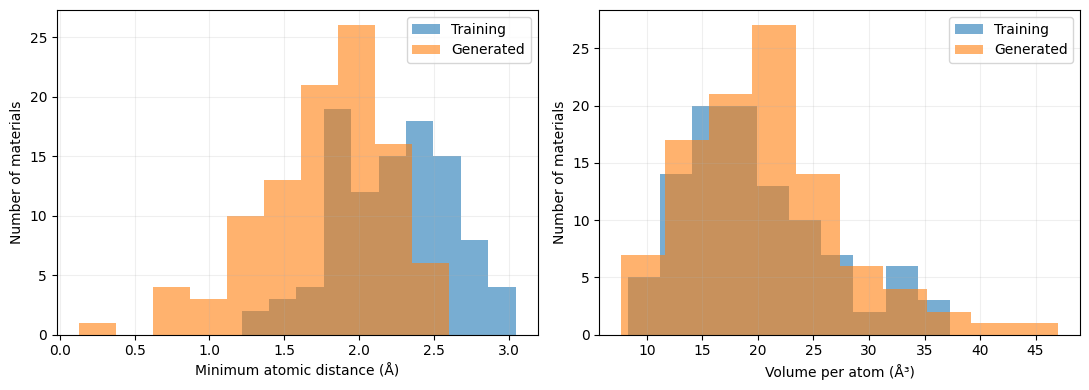

In [13]:
# Compare generated materials with training materials
from itertools import product

def material_metrics(frac_coords, lattice):
    frac_coords = np.asarray(frac_coords) % 1.0
    lattice = np.asarray(lattice)
    volume = abs(np.linalg.det(lattice))
    if not np.isfinite(volume) or volume < 1e-3:
        return np.nan, np.nan
    shifts = np.array(list(product([-1, 0, 1], repeat=3)))
    distances = []
    for i in range(len(frac_coords)):
        for j in range(i + 1, len(frac_coords)):
            delta = frac_coords[i] - frac_coords[j]
            displacement = (delta + shifts) @ lattice
            distances.append(np.linalg.norm(displacement, axis=1).min())
    return min(distances), volume / len(frac_coords)

# Generate materials using the EMA model
n_samples = 100
num_time_steps = 100
ema_net.eval()
start = time.time()
with torch.no_grad():
    batch_x1, batch_a1, batch_l1 = ema_net.generate_process_fm(n_samples, sz_fixed, num_time_steps)
print('Time(sec) :',time.time()-start)

# Convert generated data to physical units
gen_x = batch_x1.detach().cpu().numpy()
gen_l = batch_l1.detach().cpu().numpy()
gen_x = (gen_x * np.asarray(atom_dict.frac_coord_std) + np.asarray(atom_dict.frac_coord_mean)) % 1.0
gen_l = gen_l * np.asarray(atom_dict.lattice_std) + np.asarray(atom_dict.lattice_mean)

# Select real training materials of the same size
indices = np.random.choice(len(group_dataset[sz_fixed]), n_samples, replace=False)
train_materials = [group_dataset[sz_fixed][i] for i in indices]

# Compute geometric metrics
gen_metrics = np.array([material_metrics(x, l) for x, l in zip(gen_x, gen_l)])
train_metrics = np.array([material_metrics(m.frac_coords.cpu().numpy(), m.lattice_matrix.cpu().numpy()) for m in train_materials])

# Report preliminary structural validity
valid = np.isfinite(gen_metrics[:, 0]) & (gen_metrics[:, 0] > 0.5)
print('Generated materials:', n_samples)
print(f'Basic geometric validity: {100 * valid.mean():.1f}%')
print('Mean minimum distance (generated):', np.nanmean(gen_metrics[:, 0]))
print('Mean minimum distance (training):', np.nanmean(train_metrics[:, 0]))

# Compare distributions
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
labels = ['Minimum atomic distance (Å)', 'Volume per atom (Å³)']

for k, ax in enumerate(axes):
    train_values = train_metrics[:, k]
    gen_values = gen_metrics[:, k]
    ax.hist(train_values[np.isfinite(train_values)], bins=10, alpha=0.6, label='Training')
    ax.hist(gen_values[np.isfinite(gen_values)], bins=10, alpha=0.6, label='Generated')
    ax.set_xlabel(labels[k])
    ax.set_ylabel('Number of materials')
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


## Results after 1,000 epochs

<table align="center"> <tr> <td align="center"> <img src="pics/result_1000epochs.png" width="900"> </td> </tr> </table>
